In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\ashun\Downloads\flight_data_2024_final_cleaned.csv"

df = pd.read_csv(file_path, low_memory=False)
sample_df = df.sample(n=50000, random_state=42)

print("Full dataset:", df.shape)
print("EDA sample:", sample_df.shape)
print("Average departure delay:",
      round(sample_df["dep_delay"].mean(), 2), "minutes")
print("Average arrival delay:",
      round(sample_df["arr_delay"].mean(), 2), "minutes")


Full dataset: (3538856, 35)
EDA sample: (50000, 35)
Average departure delay: 13.77 minutes
Average arrival delay: 8.27 minutes


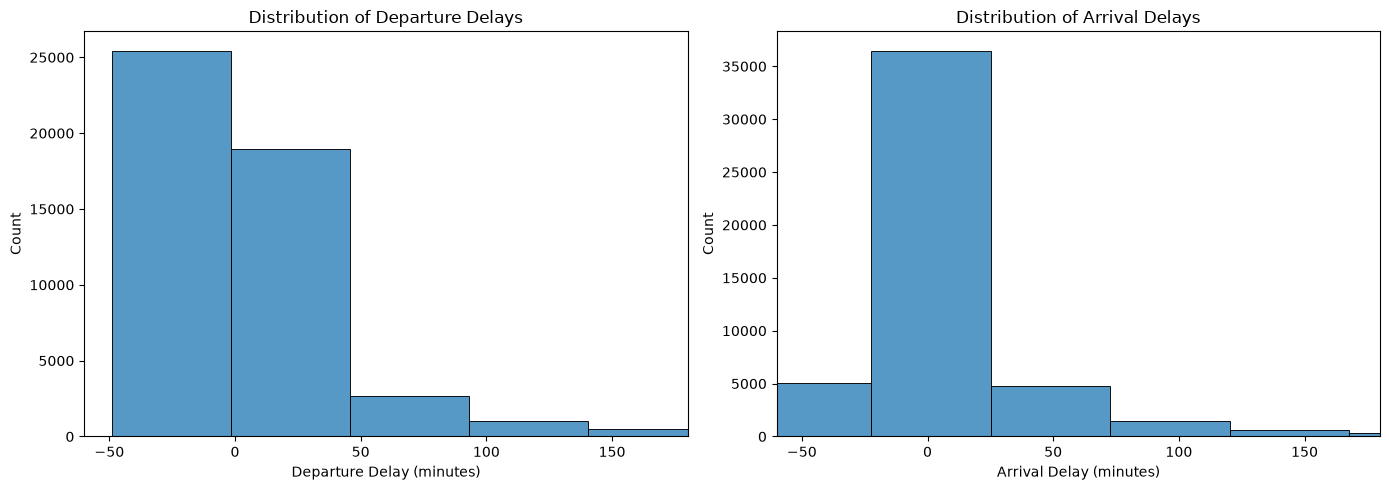

In [3]:

# Distribution of flight delays
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(sample_df["dep_delay"].dropna(),
             bins=50, ax=axes[0])
axes[0].set_title("Distribution of Departure Delays")
axes[0].set_xlabel("Departure Delay (minutes)")
axes[0].set_xlim(-60, 180)

sns.histplot(sample_df["arr_delay"].dropna(),
             bins=50, ax=axes[1])
axes[1].set_title("Distribution of Arrival Delays")
axes[1].set_xlabel("Arrival Delay (minutes)")
axes[1].set_xlim(-60, 180)

plt.tight_layout()
plt.show()


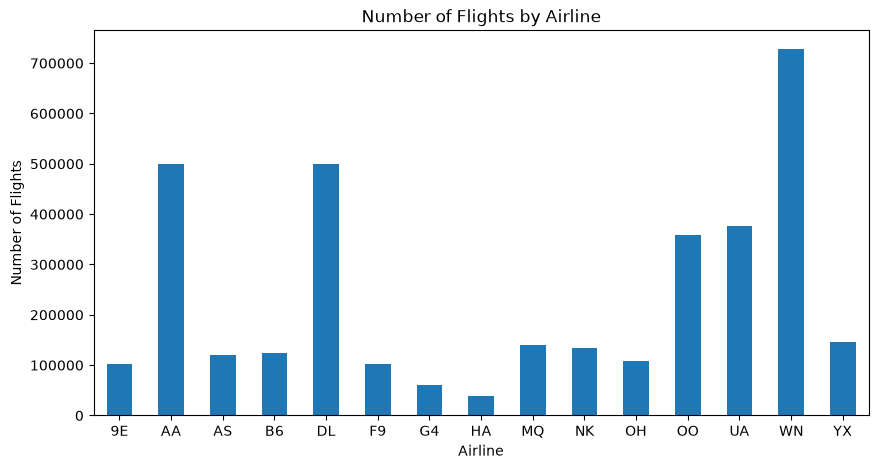

In [9]:
flight_count = df['op_unique_carrier'].value_counts().sort_index()

flight_count.plot(kind='bar', figsize=(10,5))
plt.title('Number of Flights by Airline')
plt.xlabel('Airline')
plt.ylabel('Number of Flights')
plt.xticks(rotation=0)
plt.show()

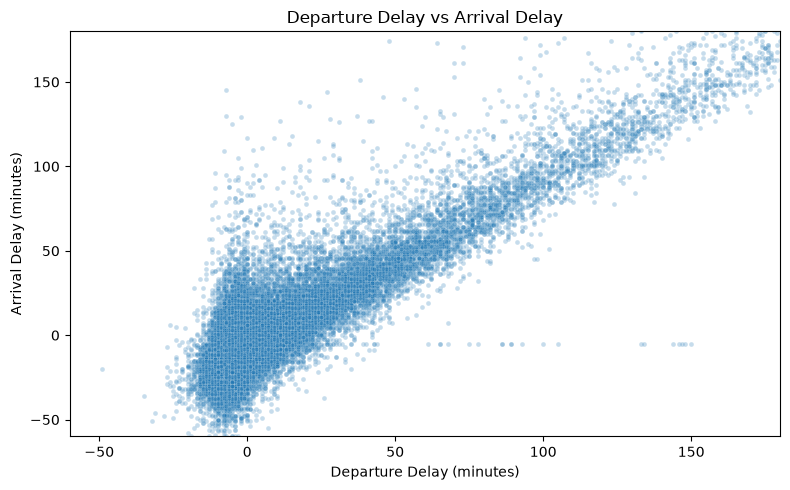

Correlation: 0.967


In [4]:

# Relationship between departure and arrival delays
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_df,
    x="dep_delay",
    y="arr_delay",
    alpha=0.25,
    s=12
)

plt.xlim(-60, 180)
plt.ylim(-60, 180)
plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Arrival Delay (minutes)")
plt.tight_layout()
plt.show()

print("Correlation:",
      round(sample_df["dep_delay"].corr(
          sample_df["arr_delay"]), 3))


In [10]:
# Correlation between Departure Delay and Arrival Delay

correlation = df['dep_delay'].corr(df['arr_delay'])

print("Correlation coefficient:", correlation)

if correlation > 0.7:
    print("Interpretation: Strong positive correlation")
elif correlation > 0.3:
    print("Interpretation: Moderate positive correlation")
elif correlation > 0:
    print("Interpretation: Weak positive correlation")
elif correlation < -0.7:
    print("Interpretation: Strong negative correlation")
elif correlation < -0.3:
    print("Interpretation: Moderate negative correlation")
else:
    print("Interpretation: Weak or no correlation")

Correlation coefficient: 0.9664524830919139
Interpretation: Strong positive correlation


In [11]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nNumerical summary:")
print(df.describe())

Dataset shape: (3538856, 35)

Missing values:
dep_time                 47192
dep_delay                47390
taxi_out                 48797
wheels_off               48797
wheels_on                49107
taxi_in                  49107
arr_time                 49107
arr_delay                49107
cancellation_code      3489749
actual_elapsed_time      49107
air_time                 49107
dtype: int64

Duplicate rows: 0

Data types:
year                     int64
month                    int64
day_of_month             int64
day_of_week              int64
fl_date                    str
op_unique_carrier          str
op_carrier_fl_num      float64
origin                     str
origin_city_name           str
origin_state_nm            str
dest                       str
dest_city_name             str
dest_state_nm              str
crs_dep_time             int64
dep_time               float64
dep_delay              float64
taxi_out               float64
wheels_off             float64
wheels_on 

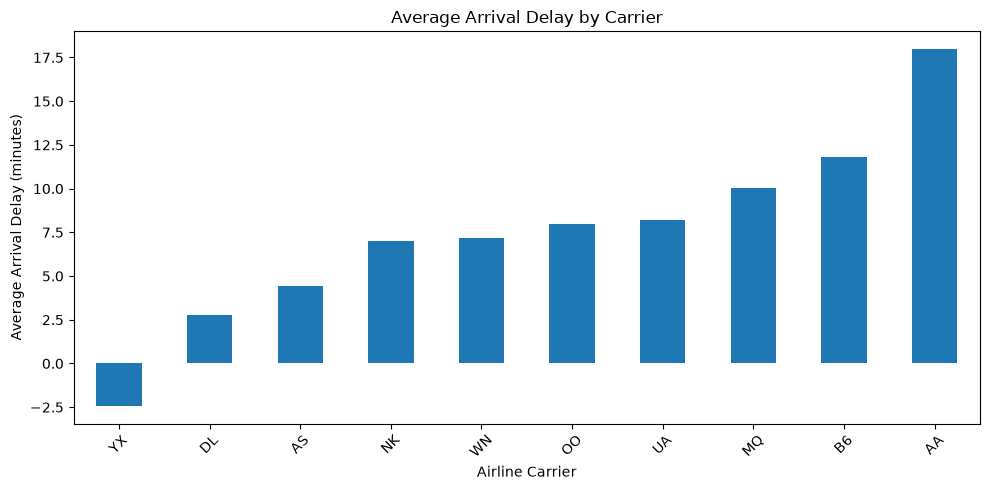

In [5]:

# Average arrival delay for the 10 busiest carriers
top_carriers = sample_df["op_unique_carrier"].value_counts().head(10).index

carrier_delay = (
    sample_df[sample_df["op_unique_carrier"].isin(top_carriers)]
    .groupby("op_unique_carrier")["arr_delay"]
    .mean()
    .sort_values()
)

carrier_delay.plot(kind="bar", figsize=(10, 5))
plt.title("Average Arrival Delay by Carrier")
plt.xlabel("Airline Carrier")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Week 4: EDA Findings

- **Univariate analysis:** Examined departure and arrival delay distributions.
- **Bivariate analysis:** Investigated the relationship between departure and arrival delays using a scatter plot and correlation.
- **Categorical analysis:** Compared average arrival delays across the 10 busiest carriers.
- **Conclusion:** These visualizations help identify delay patterns and differences between airlines. Findings are based on a random sample of 50,000 flights.